## Part A - Decision Tree from Scratch
• Using NumPy/Pandas, implement Gini impurity and entropy, choose feature-threshold splits, construct
the tree recursively with stopping rules, and write a prediction function.
• Using variance and skewness, plot decision boundaries for the manual and Scikit-learn trees; also
visualize the learned manual tree and its split rules.
• Explore criterion and maximum-depth settings; compare predictions and performance against
Scikit-learn DecisionTreeClassifier.

In [1]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

OUTPUT_DIR = "results"
PLOT_DIR = "plots"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

DATA_PATH = "data_banknote_authentication.txt"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Place data_banknote_authentication.txt in the notebook folder."
    )

columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(DATA_PATH, header=None, names=columns)

print("Dataset shape:", df.shape)
display(df.head())
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["class"].value_counts())


Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000



Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Class distribution:
class
0    762
1    610
Name: count, dtype: int64


In [3]:

FEATURES_2D = ["variance", "skewness"]
FEATURES_ALL = ["variance", "skewness", "curtosis", "entropy"]

X = df[FEATURES_ALL].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

# One consistent train-test split for all four-feature models
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

# Identify the two plotting features by their column positions
X_train_2d = X_train[:, :2]
X_test_2d = X_test[:, :2]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)


Training samples: 1029
Testing samples: 343
Training feature shape: (1029, 4)
Testing feature shape: (343, 4)


In [4]:

def gini_impurity(y):
    """Calculate Gini impurity for a target array."""
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1.0 - np.sum(probabilities ** 2)


def entropy(y):
    """Calculate Shannon entropy in bits."""
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(
        probabilities * np.log2(probabilities)
    )


sample_labels = np.array([0, 0, 1, 1])

print("Gini impurity:", gini_impurity(sample_labels))
print("Entropy:", entropy(sample_labels))


Gini impurity: 0.5
Entropy: 1.0


In [5]:

class DecisionTreeScratch:
    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=1
    ):
        if criterion not in ("gini", "entropy"):
            raise ValueError("criterion must be 'gini' or 'entropy'")

        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.tree = None

    def _impurity(self, y):
        if self.criterion == "gini":
            return gini_impurity(y)
        return entropy(y)

    def _best_split(self, X, y):
        n_samples, n_features = X.shape
        parent_impurity = self._impurity(y)

        best_gain = 0.0
        best_split = None

        for feature in range(n_features):
            values = np.unique(X[:, feature])

            if len(values) < 2:
                continue

            thresholds = (values[:-1] + values[1:]) / 2.0

            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = ~left_mask

                n_left = np.sum(left_mask)
                n_right = np.sum(right_mask)

                if (
                    n_left < self.min_samples_leaf
                    or n_right < self.min_samples_leaf
                ):
                    continue

                y_left = y[left_mask]
                y_right = y[right_mask]

                weighted_impurity = (
                    n_left / n_samples * self._impurity(y_left)
                    + n_right / n_samples * self._impurity(y_right)
                )

                gain = parent_impurity - weighted_impurity

                if gain > best_gain:
                    best_gain = gain
                    best_split = {
                        "feature": feature,
                        "threshold": float(threshold),
                        "gain": float(gain),
                        "left_mask": left_mask,
                        "right_mask": right_mask
                    }

        return best_split

    def _build_tree(self, X, y, depth):
        values, counts = np.unique(y, return_counts=True)
        majority_class = int(values[np.argmax(counts)])

        node = {
            "prediction": majority_class,
            "samples": len(y),
            "impurity": float(self._impurity(y)),
            "depth": depth
        }

        stop = (
            len(values) == 1
            or len(y) < self.min_samples_split
            or (
                self.max_depth is not None
                and depth >= self.max_depth
            )
        )

        if stop:
            return node

        split = self._best_split(X, y)

        if split is None:
            return node

        node.update({
            "feature": split["feature"],
            "threshold": split["threshold"],
            "gain": split["gain"],
            "left": self._build_tree(
                X[split["left_mask"]],
                y[split["left_mask"]],
                depth + 1
            ),
            "right": self._build_tree(
                X[split["right_mask"]],
                y[split["right_mask"]],
                depth + 1
            )
        })

        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)

        self.tree = self._build_tree(X, y, depth=0)
        return self

    def _predict_one(self, x, node):
        if "feature" not in node:
            return node["prediction"]

        if x[node["feature"]] <= node["threshold"]:
            return self._predict_one(x, node["left"])

        return self._predict_one(x, node["right"])

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        return np.array([
            self._predict_one(row, self.tree)
            for row in X
        ])

    def print_tree(self, feature_names, node=None, indent=""):
        if node is None:
            node = self.tree

        if "feature" not in node:
            print(
                indent + f"Predict class {node['prediction']} "
                f"(samples={node['samples']})"
            )
            return

        feature_name = feature_names[node["feature"]]
        threshold = node["threshold"]

        print(
            indent + f"IF {feature_name} <= {threshold:.4f} "
            f"(gain={node['gain']:.4f})"
        )

        self.print_tree(
            feature_names, node["left"], indent + "  "
        )

        print(indent + "ELSE")

        self.print_tree(
            feature_names, node["right"], indent + "  "
        )


manual_tree = DecisionTreeScratch(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=2
)

manual_tree.fit(X_train_2d, y_train)

print("Manual Decision Tree split rules:")
manual_tree.print_tree(FEATURES_2D)


Manual Decision Tree split rules:
IF variance <= 0.7651 (gain=0.2435)
  IF skewness <= 5.1608 (gain=0.1596)
    IF variance <= 0.3202 (gain=0.0222)
      IF variance <= -0.4586 (gain=0.0048)
        IF skewness <= 0.0548 (gain=0.0022)
          Predict class 1 (samples=193)
        ELSE
          Predict class 1 (samples=135)
      ELSE
        IF skewness <= -0.1759 (gain=0.0824)
          Predict class 1 (samples=24)
        ELSE
          Predict class 1 (samples=38)
    ELSE
      IF skewness <= 0.9819 (gain=0.1152)
        IF skewness <= 0.6818 (gain=0.0754)
          Predict class 0 (samples=22)
        ELSE
          Predict class 0 (samples=5)
      ELSE
        IF skewness <= 3.2197 (gain=0.0380)
          Predict class 1 (samples=7)
        ELSE
          Predict class 1 (samples=12)
  ELSE
    IF variance <= -3.4311 (gain=0.3180)
      IF variance <= -4.3819 (gain=0.0343)
        Predict class 1 (samples=25)
      ELSE
        Predict class 0 (samples=2)
    ELSE
      IF sk

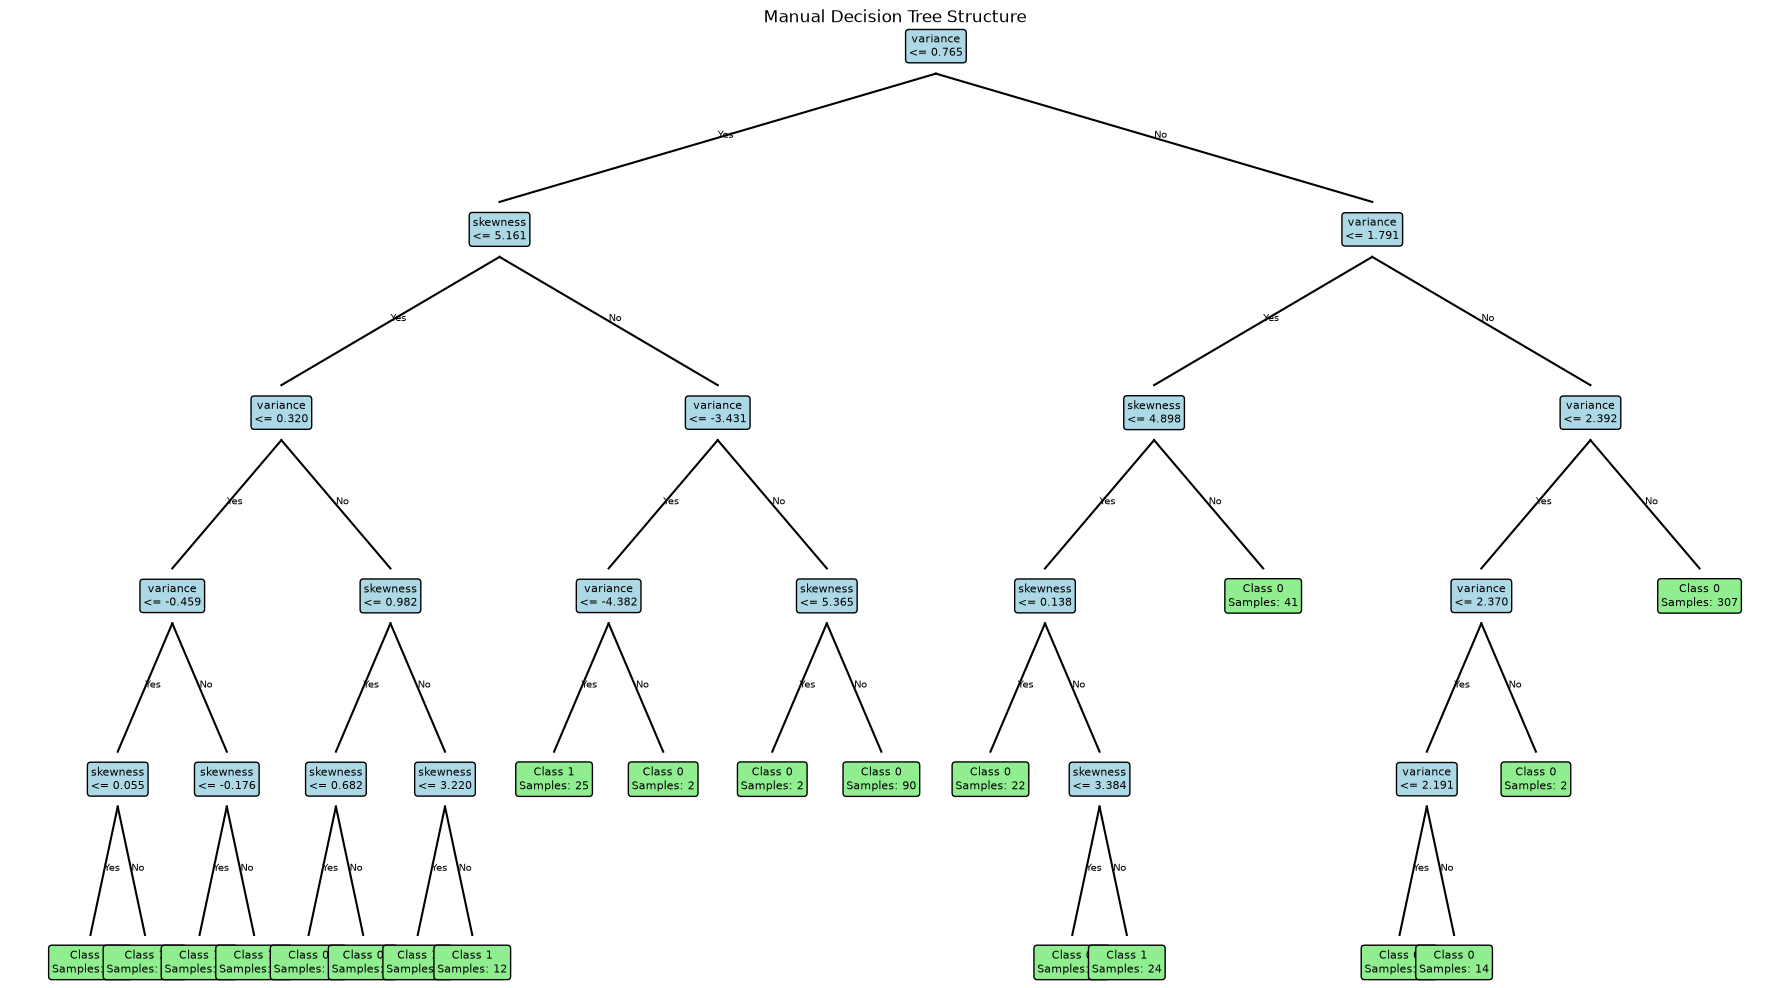

In [6]:

def draw_manual_tree(node, feature_names, ax, x, y, dx, depth=0):
    if "feature" not in node:
        ax.text(
            x, y,
            f"Class {node['prediction']}\n"
            f"Samples: {node['samples']}",
            ha="center",
            va="center",
            fontsize=8,
            bbox=dict(boxstyle="round", facecolor="lightgreen")
        )
        return

    label = (
        f"{feature_names[node['feature']]}\n"
        f"<= {node['threshold']:.3f}"
    )

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=8,
        bbox=dict(boxstyle="round", facecolor="lightblue")
    )

    child_y = y - 1.0
    left_x = x - dx
    right_x = x + dx

    ax.plot([x, left_x], [y - 0.15, child_y + 0.15], "k-")
    ax.plot([x, right_x], [y - 0.15, child_y + 0.15], "k-")

    ax.text((x + left_x) / 2, (y + child_y) / 2, "Yes", fontsize=7)
    ax.text((x + right_x) / 2, (y + child_y) / 2, "No", fontsize=7)

    draw_manual_tree(
        node["left"], feature_names, ax,
        left_x, child_y, dx / 2, depth + 1
    )

    draw_manual_tree(
        node["right"], feature_names, ax,
        right_x, child_y, dx / 2, depth + 1
    )


fig, ax = plt.subplots(figsize=(18, 10))

draw_manual_tree(
    manual_tree.tree,
    FEATURES_2D,
    ax,
    x=0,
    y=0,
    dx=5
)

ax.set_title("Manual Decision Tree Structure")
ax.axis("off")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/manual_decision_tree.png", dpi=200)
plt.show()


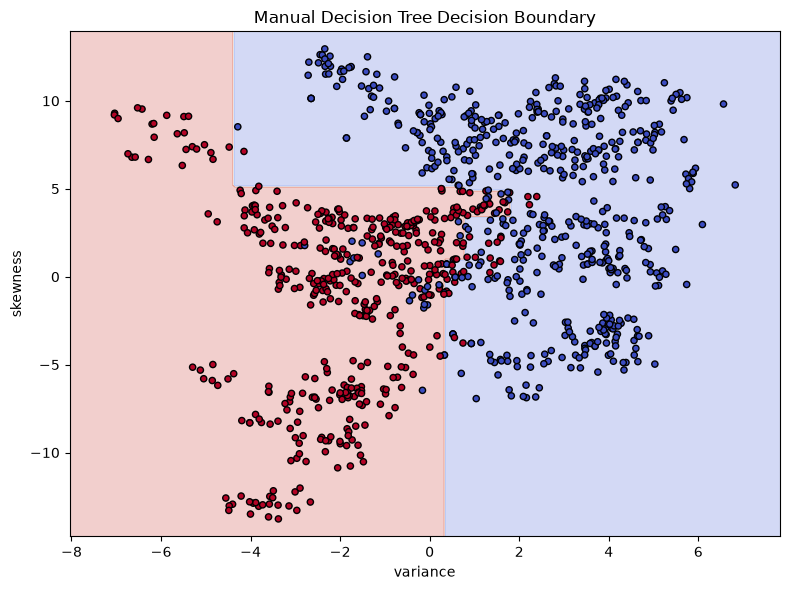

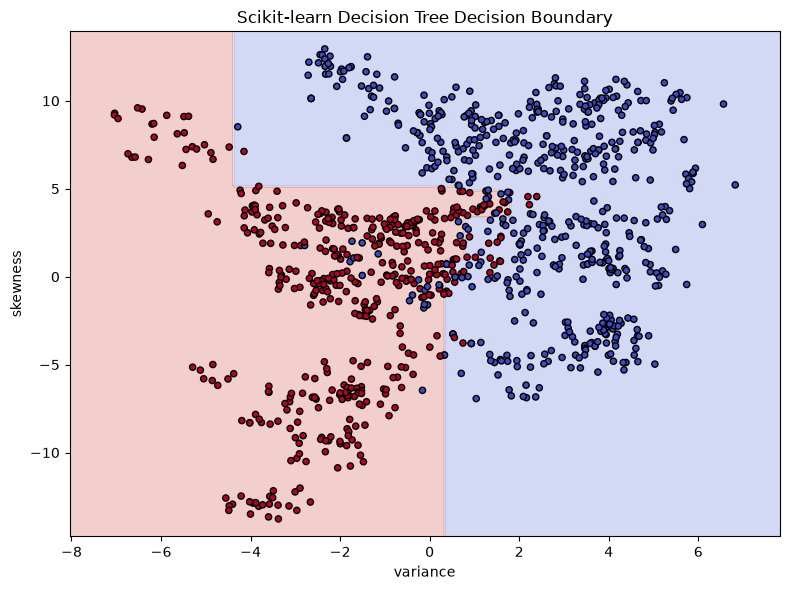

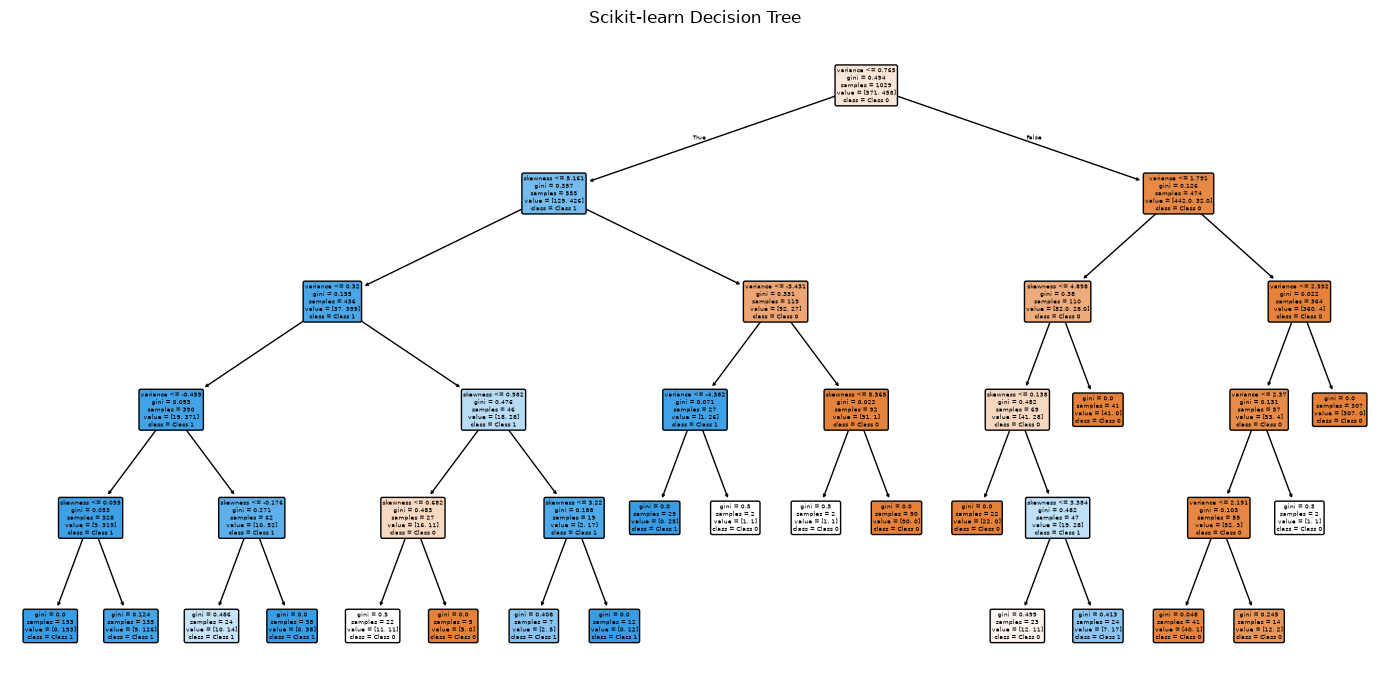

In [7]:

def plot_boundary(
    model, X, y, title, filename,
    feature_names=FEATURES_2D
):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(
        xx, yy, predictions,
        alpha=0.25, cmap="coolwarm"
    )
    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap="coolwarm",
        edgecolors="black", s=20
    )

    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title(title)
    plt.tight_layout()
    plt.savefig(f"{PLOT_DIR}/{filename}", dpi=200)
    plt.show()


plot_boundary(
    manual_tree,
    X_train_2d,
    y_train,
    "Manual Decision Tree Decision Boundary",
    "manual_tree_boundary.png"
)

sk_tree_2d = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_leaf=2,
    random_state=RANDOM_STATE
)

sk_tree_2d.fit(X_train_2d, y_train)

plot_boundary(
    sk_tree_2d,
    X_train_2d,
    y_train,
    "Scikit-learn Decision Tree Decision Boundary",
    "sklearn_tree_boundary.png"
)

plt.figure(figsize=(14, 7))
plot_tree(
    sk_tree_2d,
    feature_names=FEATURES_2D,
    class_names=["Class 0", "Class 1"],
    filled=True,
    rounded=True
)
plt.title("Scikit-learn Decision Tree")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/sklearn_decision_tree.png", dpi=200)
plt.show()


In [8]:

tree_results = []

for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 5, 8, None]:
        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=RANDOM_STATE
        )

        start = time.perf_counter()
        model.fit(X_train, y_train)
        train_time = time.perf_counter() - start

        start = time.perf_counter()
        predictions = model.predict(X_test)
        prediction_time = time.perf_counter() - start

        tree_results.append({
            "criterion": criterion,
            "max_depth": depth,
            "accuracy": accuracy_score(y_test, predictions),
            "train_time_sec": train_time,
            "prediction_time_sec": prediction_time,
            "tree_depth": model.get_depth(),
            "leaf_nodes": model.get_n_leaves()
        })

tree_results_df = pd.DataFrame(tree_results)
display(tree_results_df)

tree_results_df.to_csv(
    f"{OUTPUT_DIR}/tree_depth_comparison.csv",
    index=False
)


,criterion,max_depth,accuracy,train_time_sec,prediction_time_sec,tree_depth,leaf_nodes
0,gini,2.0,0.874636,0.001798,0.000220,2,4
1,gini,3.0,0.918367,0.001973,0.000161,3,8
2,gini,5.0,0.985423,0.001544,0.000144,5,20
3,gini,8.0,0.985423,0.001747,0.000205,7,24
4,gini,NaN,0.985423,0.002705,0.000358,7,24
5,entropy,2.0,0.865889,0.001717,0.000328,2,4
6,entropy,3.0,0.930029,0.001929,0.000177,3,7
7,entropy,5.0,0.965015,0.001715,0.000143,5,13
8,entropy,8.0,0.988338,0.001689,0.000165,7,18
9,entropy,NaN,0.988338,0.001674,0.000122,7,18


## Part B - Linear SVM from Scratch
• Scale input features using training-set statistics and map the binary labels to -1 and +1. Implement a
linear soft-margin SVM using hinge loss and gradient/subgradient descent in NumPy.
• With the same two features, plot manual and Scikit-learn SVM decision boundaries. Show the
separating line, +1/-1 margins, and margin-violating samples for the manual model.
• Compare against Scikit-learn linear SVM; study the effect of regularization (C), learning rate, and
iterations.

In [9]:

scaler_2d = StandardScaler()

X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

y_train_svm = np.where(y_train == 0, -1, 1)
y_test_svm = np.where(y_test == 0, -1, 1)

print("Scaled training features:")
print(X_train_2d_scaled[:5])
print("SVM labels:", np.unique(y_train_svm))


Scaled training features:
[[ 1.15443096  0.15602544]
 [-1.00020506 -1.15334626]
 [-0.82636283  1.03356406]
 [ 0.30121582 -1.08221353]
 [-1.33869358 -0.30462001]]
SVM labels: [-1  1]


In [10]:

class LinearSVMScratch:
    def __init__(
        self,
        learning_rate=0.001,
        C=1.0,
        epochs=2000
    ):
        self.learning_rate = learning_rate
        self.C = C
        self.epochs = epochs
        self.w = None
        self.b = 0.0
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.loss_history = []

        for epoch in range(self.epochs):
            margins = y * (X @ self.w + self.b)
            active = margins < 1

            # Objective: 0.5 * ||w||^2
            #            + C/n * sum(hinge loss)
            grad_w = self.w.copy()
            grad_b = 0.0

            if np.any(active):
                grad_w -= (
                    self.C / n_samples
                ) * (X[active].T @ y[active])

                grad_b -= (
                    self.C / n_samples
                ) * np.sum(y[active])

            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b

            if epoch % 100 == 0 or epoch == self.epochs - 1:
                hinge = np.maximum(
                    0,
                    1 - y * (X @ self.w + self.b)
                )

                loss = (
                    0.5 * np.dot(self.w, self.w)
                    + self.C * np.mean(hinge)
                )

                self.loss_history.append(loss)

        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(
            self.decision_function(X) >= 0,
            1,
            -1
        )


manual_svm = LinearSVMScratch(
    learning_rate=0.01,
    C=1.0,
    epochs=3000
)

manual_svm.fit(X_train_2d_scaled, y_train_svm)

print("Weights:", manual_svm.w)
print("Bias:", manual_svm.b)
print("Training completed.")


Weights: [-0.50021776 -0.25496919]
Bias: -0.28867832847423675
Training completed.


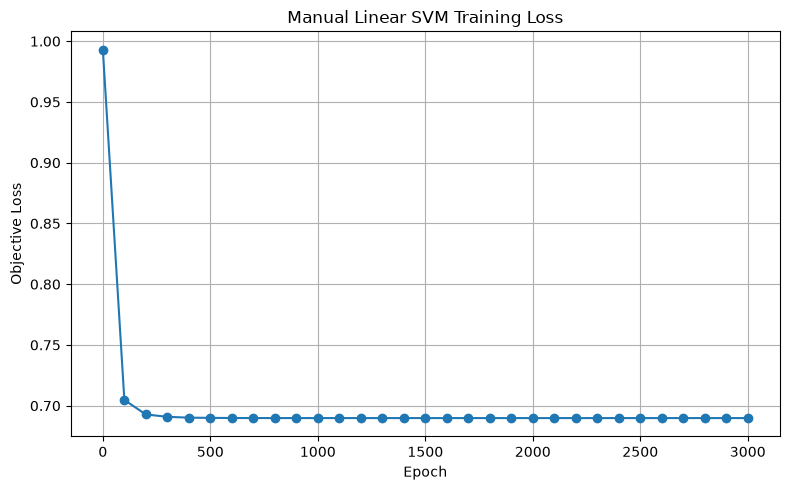

In [11]:

plt.figure(figsize=(8, 5))

plt.plot(
    np.arange(len(manual_svm.loss_history)) * 100,
    manual_svm.loss_history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Objective Loss")
plt.title("Manual Linear SVM Training Loss")
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/svm_training_loss.png", dpi=200)
plt.show()


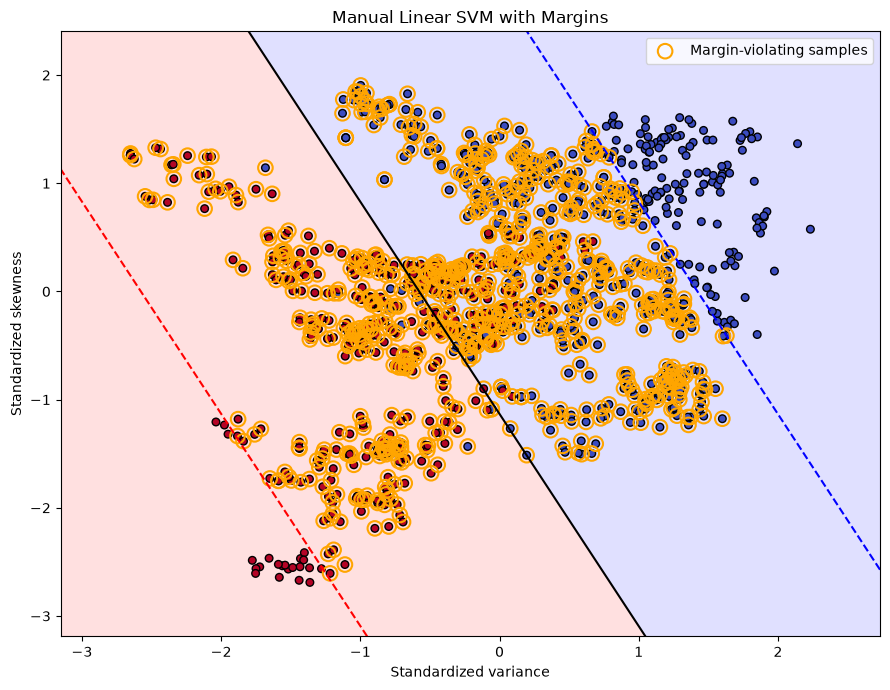

In [12]:

def plot_svm_margins(model, X, y, title, filename):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = model.decision_function(grid).reshape(xx.shape)

    plt.figure(figsize=(9, 7))

    plt.contourf(
        xx, yy, scores,
        levels=[-100, 0, 100],
        alpha=0.12,
        colors=["blue", "red"]
    )

    # Separating line and two margin lines
    plt.contour(
        xx, yy, scores,
        levels=[-1, 0, 1],
        colors=["blue", "black", "red"],
        linestyles=["--", "-", "--"]
    )

    predictions = model.predict(X)
    margins = y * model.decision_function(X)
    violating = margins < 1

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap="coolwarm",
        edgecolors="black", s=30
    )

    plt.scatter(
        X[violating, 0],
        X[violating, 1],
        s=110,
        facecolors="none",
        edgecolors="orange",
        linewidths=1.5,
        label="Margin-violating samples"
    )

    plt.xlabel("Standardized variance")
    plt.ylabel("Standardized skewness")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{PLOT_DIR}/{filename}", dpi=200)
    plt.show()


plot_svm_margins(
    manual_svm,
    X_train_2d_scaled,
    y_train_svm,
    "Manual Linear SVM with Margins",
    "manual_svm_margins.png"
)


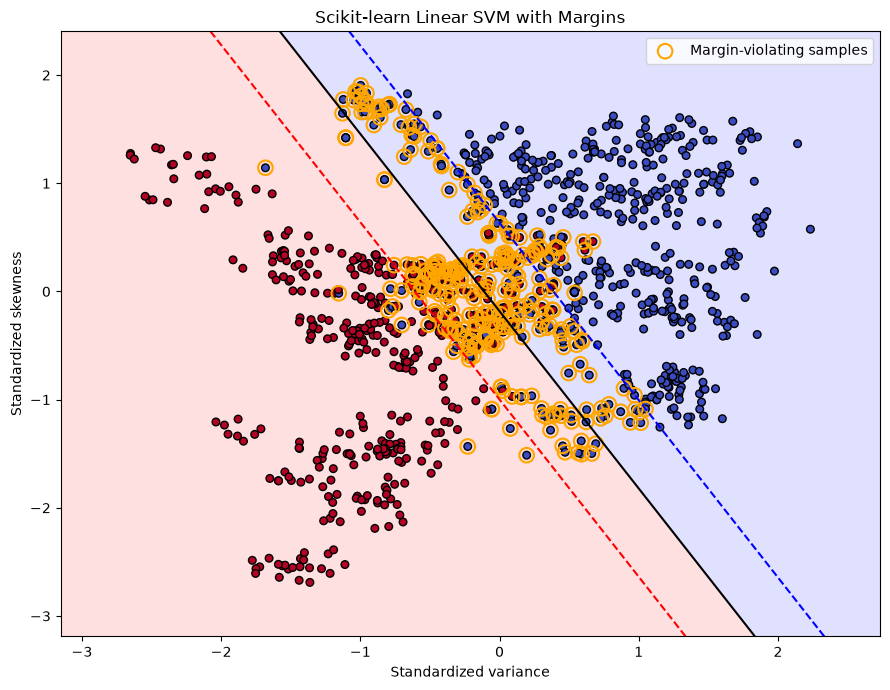

Manual SVM accuracy: 0.8717201166180758
Scikit-learn SVM accuracy: 0.8892128279883382


In [13]:

sk_svm_2d = SVC(
    kernel="linear",
    C=1.0
)

sk_svm_2d.fit(X_train_2d_scaled, y_train_svm)

plot_svm_margins(
    sk_svm_2d,
    X_train_2d_scaled,
    y_train_svm,
    "Scikit-learn Linear SVM with Margins",
    "sklearn_svm_margins.png"
)

manual_pred_2d = manual_svm.predict(X_test_2d_scaled)
sk_pred_2d = sk_svm_2d.predict(X_test_2d_scaled)

print(
    "Manual SVM accuracy:",
    accuracy_score(y_test_svm, manual_pred_2d)
)

print(
    "Scikit-learn SVM accuracy:",
    accuracy_score(y_test_svm, sk_pred_2d)
)


In [14]:

svm_experiments = []

for C_value in [0.01, 0.1, 1.0, 10.0]:
    for lr in [0.001, 0.01]:
        for epochs in [1000, 3000]:
            model = LinearSVMScratch(
                learning_rate=lr,
                C=C_value,
                epochs=epochs
            )

            start = time.perf_counter()
            model.fit(X_train_2d_scaled, y_train_svm)
            train_time = time.perf_counter() - start

            predictions = model.predict(X_test_2d_scaled)

            svm_experiments.append({
                "C": C_value,
                "learning_rate": lr,
                "epochs": epochs,
                "accuracy": accuracy_score(
                    y_test_svm, predictions
                ),
                "training_time_sec": train_time
            })

svm_experiments_df = pd.DataFrame(svm_experiments)
display(svm_experiments_df)

svm_experiments_df.to_csv(
    f"{OUTPUT_DIR}/svm_hyperparameter_comparison.csv",
    index=False
)


,C,learning_rate,epochs,accuracy,training_time_sec
0,0.01,0.001,1000,0.892128,0.041392
1,0.01,0.001,3000,0.880466,0.091977
2,0.01,0.010,1000,0.720117,0.033376
3,0.01,0.010,3000,0.556851,0.081124
4,0.10,0.001,1000,0.892128,0.036395
5,0.10,0.001,3000,0.880466,0.088795
6,0.10,0.010,1000,0.720117,0.024733
7,0.10,0.010,3000,0.556851,0.078912
8,1.00,0.001,1000,0.892128,0.027681
9,1.00,0.001,3000,0.886297,0.074926


## Part C - Kernel SVM and Nonlinear Boundaries
• Generate a two-dimensional nonlinear dataset using make_moons or make_circles. Train Scikit-learn
SVMs with linear, polynomial, and RBF kernels.
• Plot and compare all three decision boundaries, and explain why a nonlinear kernel may help.

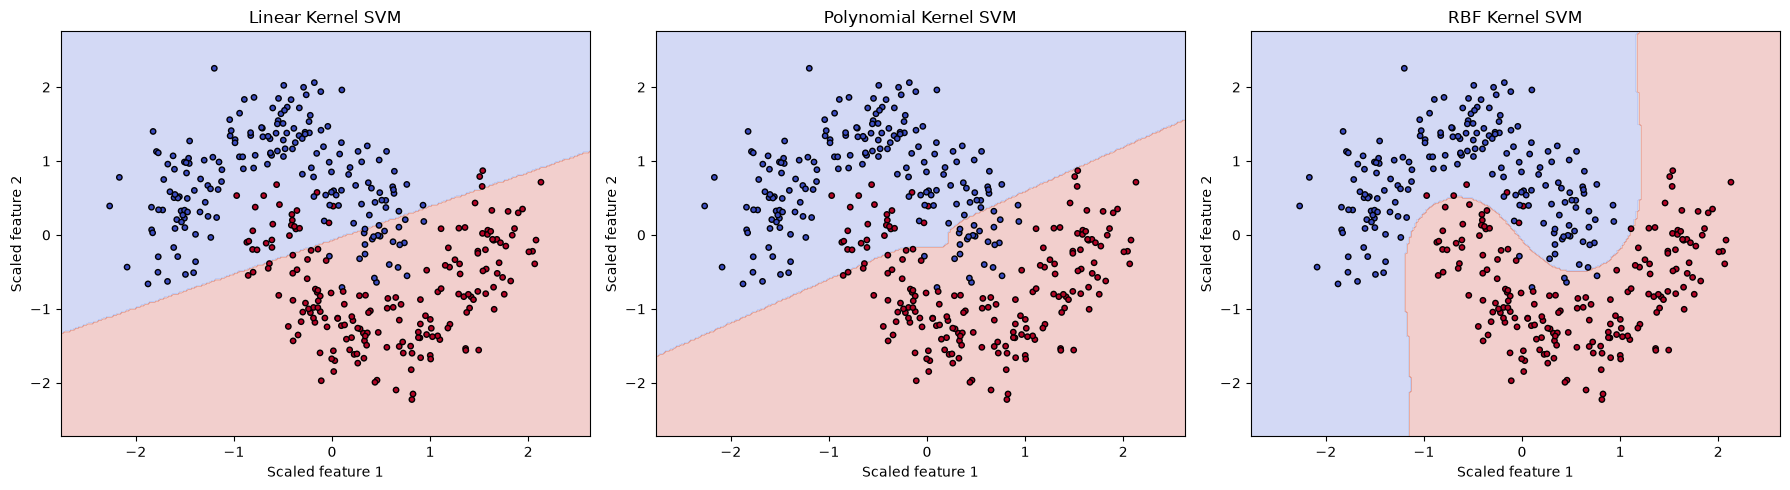

,kernel,accuracy,F1-score
0,Linear,0.856,0.852459
1,Polynomial,0.840,0.836066
2,RBF,0.984,0.983607


In [15]:

X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.20,
    random_state=RANDOM_STATE
)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = (
    train_test_split(
        X_moons,
        y_moons,
        test_size=0.25,
        random_state=RANDOM_STATE,
        stratify=y_moons
    )
)

moon_scaler = StandardScaler()

X_moons_train_scaled = moon_scaler.fit_transform(X_moons_train)
X_moons_test_scaled = moon_scaler.transform(X_moons_test)

kernels = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial": SVC(kernel="poly", degree=3, C=1.0),
    "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

moon_results = []

for ax, (name, model) in zip(axes, kernels.items()):
    model.fit(X_moons_train_scaled, y_moons_train)

    x_min, x_max = (
        X_moons_train_scaled[:, 0].min() - 0.5,
        X_moons_train_scaled[:, 0].max() + 0.5
    )
    y_min, y_max = (
        X_moons_train_scaled[:, 1].min() - 0.5,
        X_moons_train_scaled[:, 1].max() + 0.5
    )

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        alpha=0.25, cmap="coolwarm"
    )

    ax.scatter(
        X_moons_train_scaled[:, 0],
        X_moons_train_scaled[:, 1],
        c=y_moons_train,
        cmap="coolwarm",
        edgecolors="black",
        s=15
    )

    ax.set_title(f"{name} Kernel SVM")
    ax.set_xlabel("Scaled feature 1")
    ax.set_ylabel("Scaled feature 2")

    predictions = model.predict(X_moons_test_scaled)

    moon_results.append({
        "kernel": name,
        "accuracy": accuracy_score(
            y_moons_test, predictions
        ),
        "F1-score": f1_score(
            y_moons_test, predictions
        )
    })

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/kernel_svm_comparison.png", dpi=200)
plt.show()

moon_results_df = pd.DataFrame(moon_results)
display(moon_results_df)


## Part D - Final Comparison
• On the original Banknote dataset, train manual and Scikit-learn Decision Trees, manual and Scikit-learn
linear SVMs, and an RBF SVM using all four features.
• Use a consistent train-test split. Compare accuracy, precision, recall, F1-score, and training/prediction
times; discuss interpretability, scaling, overfitting, and model complexity.

In [16]:

# Scale all four features using training data only
scaler_all = StandardScaler()

X_train_scaled = scaler_all.fit_transform(X_train)
X_test_scaled = scaler_all.transform(X_test)

y_train_pm = np.where(y_train == 0, -1, 1)
y_test_pm = np.where(y_test == 0, -1, 1)

models = {}

# Manual decision tree
models["Manual Decision Tree"] = (
    DecisionTreeScratch(
        criterion="gini",
        max_depth=5,
        min_samples_leaf=2
    ),
    X_train,
    X_test,
    y_train,
    y_test,
    False
)

# Scikit-learn decision tree
models["Sklearn Decision Tree"] = (
    DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_leaf=2,
        random_state=RANDOM_STATE
    ),
    X_train,
    X_test,
    y_train,
    y_test,
    False
)

# Manual linear SVM
models["Manual Linear SVM"] = (
    LinearSVMScratch(
        learning_rate=0.01,
        C=1.0,
        epochs=3000
    ),
    X_train_scaled,
    X_test_scaled,
    y_train_pm,
    y_test_pm,
    True
)

# Scikit-learn linear SVM
models["Sklearn Linear SVM"] = (
    SVC(kernel="linear", C=1.0),
    X_train_scaled,
    X_test_scaled,
    y_train_pm,
    y_test_pm,
    True
)

# Scikit-learn RBF SVM
models["Sklearn RBF SVM"] = (
    SVC(kernel="rbf", C=1.0, gamma="scale"),
    X_train_scaled,
    X_test_scaled,
    y_train_pm,
    y_test_pm,
    True
)

final_results = []
fitted_models = {}

for name, (
    model, Xtr, Xte, ytr, yte, is_svm
) in models.items():

    start = time.perf_counter()
    model.fit(Xtr, ytr)
    training_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(Xte)
    prediction_time = time.perf_counter() - start

    if is_svm:
        predictions = np.where(predictions == -1, 0, 1)
        y_true = np.where(yte == -1, 0, 1)
    else:
        y_true = yte

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Training time (sec)": training_time,
        "Prediction time (sec)": prediction_time
    })

    fitted_models[name] = model

results_df = pd.DataFrame(final_results)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "Training time (sec)": "{:.6f}",
        "Prediction time (sec)": "{:.6f}"
    })
)

results_df.to_csv(
    f"{OUTPUT_DIR}/final_model_comparison.csv",
    index=False
)

print("Saved results to results/final_model_comparison.csv")


,Model,Accuracy,Precision,Recall,F1-score,Training time (sec),Prediction time (sec)
0,Manual Decision Tree,0.9796,0.9801,0.9737,0.9769,0.531910,0.000249
1,Sklearn Decision Tree,0.9796,0.9801,0.9737,0.9769,0.001464,0.000129
2,Manual Linear SVM,0.8921,0.9528,0.7961,0.8674,0.073191,0.000017
3,Sklearn Linear SVM,0.9767,0.9500,1.0000,0.9744,0.003972,0.000337
4,Sklearn RBF SVM,1.0000,1.0000,1.0000,1.0000,0.002356,0.001524


Saved results to results/final_model_comparison.csv


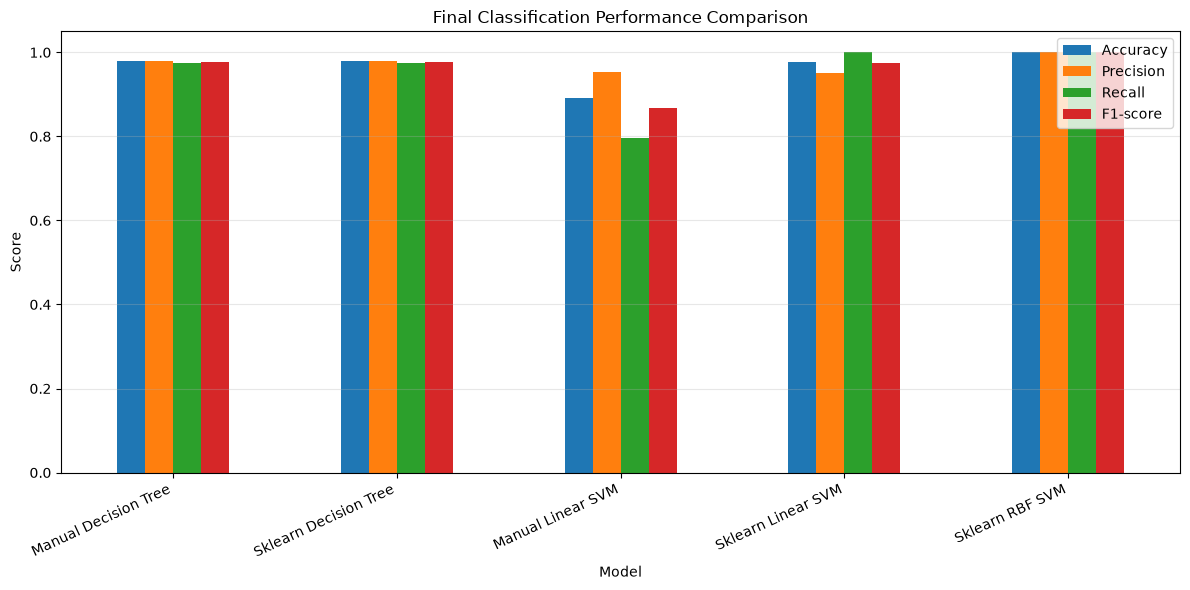

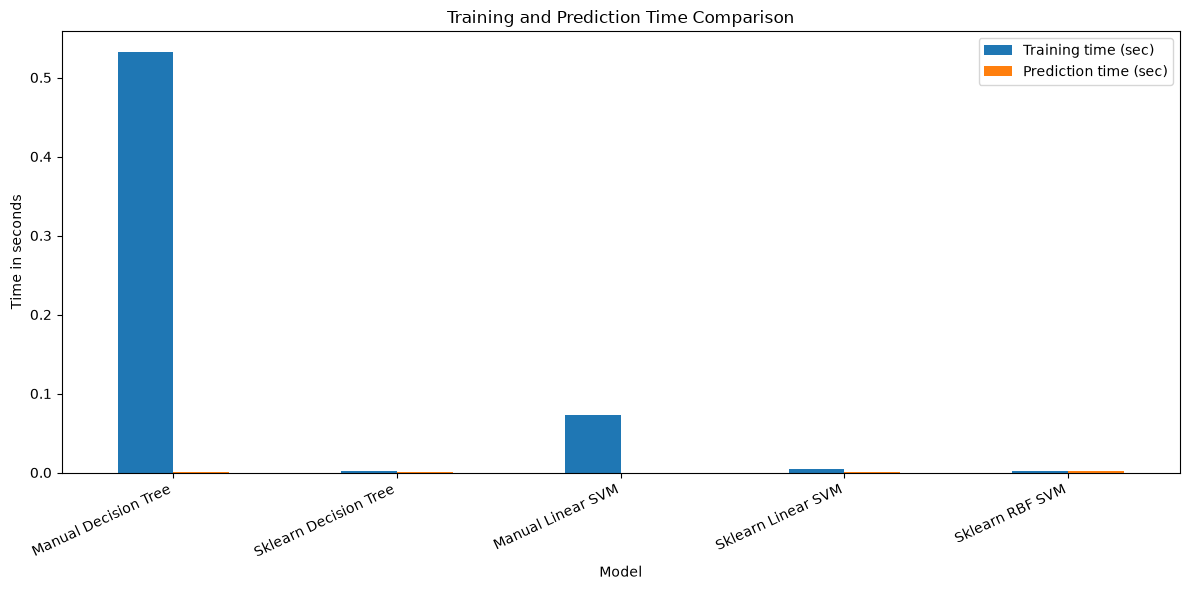

In [17]:

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05)
)

plt.title("Final Classification Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/final_metrics_comparison.png", dpi=200)
plt.show()

results_df.set_index("Model")[
    ["Training time (sec)", "Prediction time (sec)"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Training and Prediction Time Comparison")
plt.ylabel("Time in seconds")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/final_timing_comparison.png", dpi=200)
plt.show()


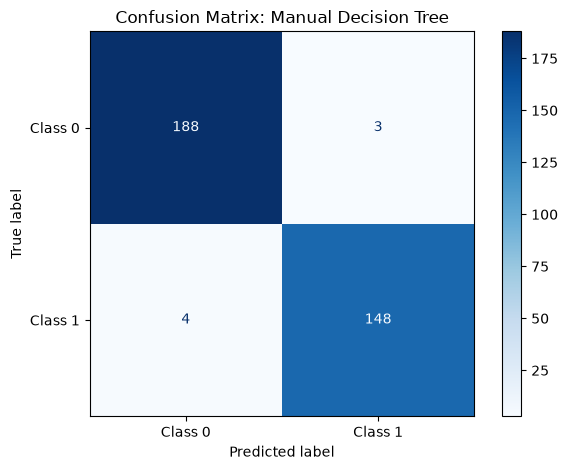

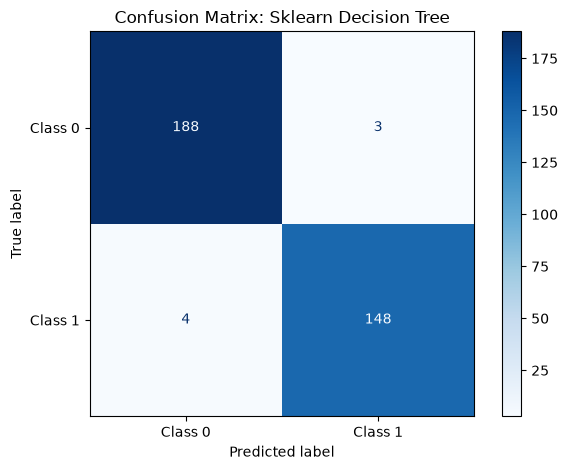

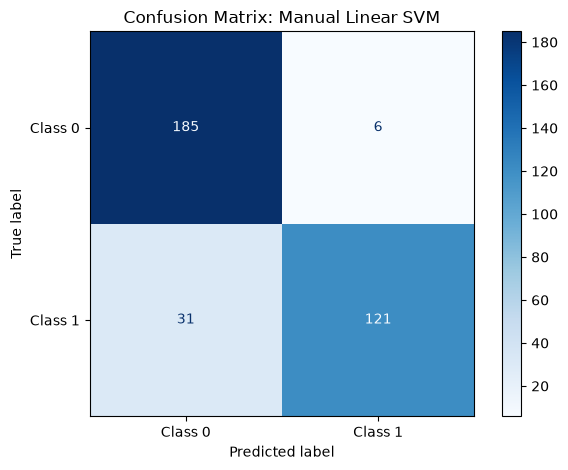

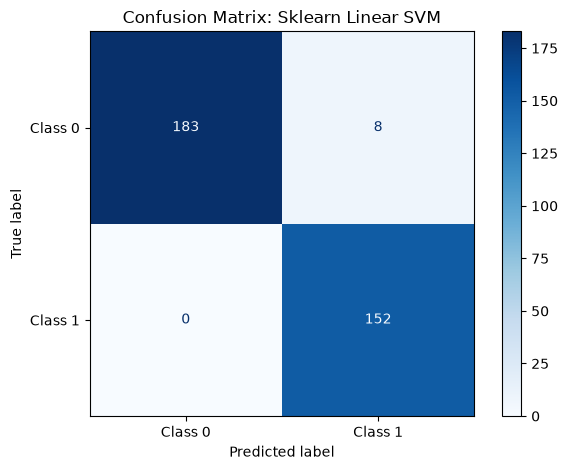

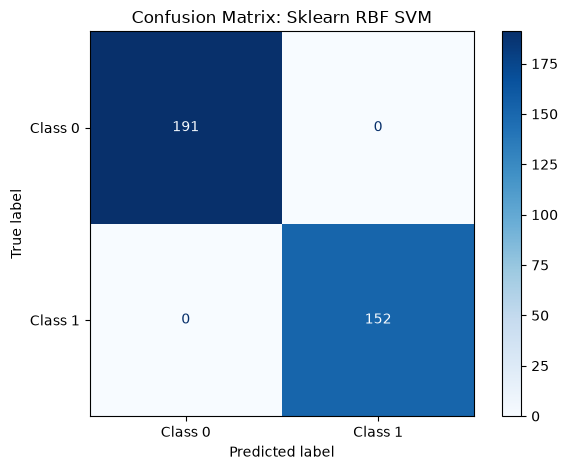

In [18]:

from sklearn.metrics import ConfusionMatrixDisplay

for name, model in fitted_models.items():
    if "SVM" in name:
        X_eval = X_test_scaled
        predictions = model.predict(X_eval)
        predictions = np.where(predictions == -1, 0, 1)
    else:
        predictions = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Class 0", "Class 1"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix: {name}")
    plt.tight_layout()

    safe_name = name.lower().replace(" ", "_")
    plt.savefig(
        f"{PLOT_DIR}/confusion_matrix_{safe_name}.png",
        dpi=200
    )

    plt.show()
